In [8]:
# ─────────────────────────────────────────────
# [C1] 환경 준비 — 라이브러리 + 한글 폰트 + 시드 고정
# ─────────────────────────────────────────────
# 필요 시 아래 주석을 해제해 설치하세요.
# !pip install numpy pandas scipy statsmodels matplotlib seaborn -q

import platform
import warnings

import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm                                   # 내장 데이터셋 로더
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd      # 사후검정(Tukey HSD)

warnings.filterwarnings("ignore")

# 재현성: 같은 난수를 항상 같게 만듭니다. (시뮬레이션 셀에 적용)
np.random.seed(42)                                                # 재현성: 난수를 항상 같게 고정

sns.set_style("whitegrid")

# 한글 폰트 설정
system = platform.system()
if system == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
elif system == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
else:
    # 리눅스·Colab에서 한글이 □□로 보이면 아래를 먼저 실행하세요.
    # !apt-get -qq install -y fonts-nanum && rm -rf ~/.cache/matplotlib
    plt.rcParams["font.family"] = "NanumGothic"

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (10, 5)


print("준비 완료!")
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("statsmodels :", sm.__version__)

준비 완료!
numpy       : 2.0.1
pandas      : 2.3.1
statsmodels : 0.15.0


In [2]:
# [C2] ── 실습 데이터 로드 — 모두 라이브러리가 제공하는 데이터셋 ──
#   · tips     (seaborn)                : 식당 영수증 → 2표본 t-test
#   · penguins (seaborn)                : 펭귄 종·체중 → 일원 ANOVA + Tukey
#   · jtrain   (statsmodels/Rdatasets)  : 같은 기업의 87/88 불량률 → 대응표본 t-test
#   · Star     (statsmodels/Rdatasets)  : Project STAR 무작위 실험 → 종합 실습 ANOVA

tips = sns.load_dataset("tips")

# 체중·종에 결측이 있는 행은 검정에서 쓸 수 없으므로 미리 제거합니다.
penguins = sns.load_dataset("penguins").dropna(subset=["body_mass_g", "species"])  # 결측(NaN) 제거

# ── 대응표본용: 같은 기업(fcode)의 1987 vs 1988 불량률을 나란히 놓기 ──
jtrain = sm.datasets.get_rdataset("jtrain", "wooldridge").data
scrap = (jtrain.pivot_table(index="fcode", columns="year", values="scrap")   # 행=기업, 열=연도
                [[1987, 1988]].dropna())                                     # 두 해 모두 기록된 기업만
before, after = scrap[1987], scrap[1988]      # '같은 기업'의 전 / 후  → 짝지어진 두 측정

# ── 종합 실습용: Project STAR (학급 유형 3종 무작위 배정) ──
star = sm.datasets.get_rdataset("Star", "Ecdat").data

print("로드 완료 ✓")
print(f"  tips     {tips.shape}  — 컬럼: {list(tips.columns)}")
print(f"  penguins {penguins.shape}  — 종: {penguins['species'].unique().tolist()}")
print(f"  scrap    {scrap.shape}   — 87·88년 모두 기록된 기업 {len(scrap)}곳의 불량률(%)")
print(f"           1987 평균 {before.mean():.2f}  →  1988 평균 {after.mean():.2f}")
print(f"  star     {star.shape} — 학급 유형: {star['classk'].unique().tolist()}")
tips.head(3)

로드 완료 ✓
  tips     (244, 7)  — 컬럼: ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']
  penguins (342, 7)  — 종: ['Adelie', 'Chinstrap', 'Gentoo']
  scrap    (54, 2)   — 87·88년 모두 기록된 기업 54곳의 불량률(%)
           1987 평균 4.61  →  1988 평균 3.79
  star     (5748, 8) — 학급 유형: ['small.class', 'regular.with.aide', 'regular']


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3


In [ ]:
# [C3] 가설검정 6단계 — tips: 남성 vs 여성 결제 금액
male   = tips[tips["sex"] == "Male"]["total_bill"]
female = tips[tips["sex"] == "Female"]["total_bill"]
alpha  = 0.05

# [3] 두 독립 집단 평균 비교 → 2표본 t-test (분산 다를 수 있으니 Welch)
t, p = stats.ttest_ind(male, female, equal_var=False)             # 두 독립 집단의 평균 비교 (equal_var=False면 Welch)

print(f"[1-2] H0: 남=여  vs  H1: 남≠여")
print(f"      남 평균 {male.mean():.2f} (n={len(male)})  /  여 평균 {female.mean():.2f} (n={len(female)})")
print(f"[4]   t = {t:.2f},  p = {p:.3f}")
print(f"[5]   p {'<' if p<alpha else '≥'} α(={alpha}) → H0 {'기각: 차이 있다' if p<alpha else '기각 못함'}")
print(f"[6]   해석: 남성 결제 금액이 통계적으로 유의하게 높습니다. (단, '얼마나' 큰지는 Part 7)")

[1-2] H0: 남=여  vs  H1: 남≠여
      남 평균 20.74 (n=157)  /  여 평균 18.06 (n=87)
[4]   t = 2.37,  p = 0.019
[5]   p < α(=0.05) → H0 기각: 차이 있다
[6]   해석: 남성 결제 금액이 통계적으로 유의하게 높습니다. (단, '얼마나' 큰지는 Part 7)


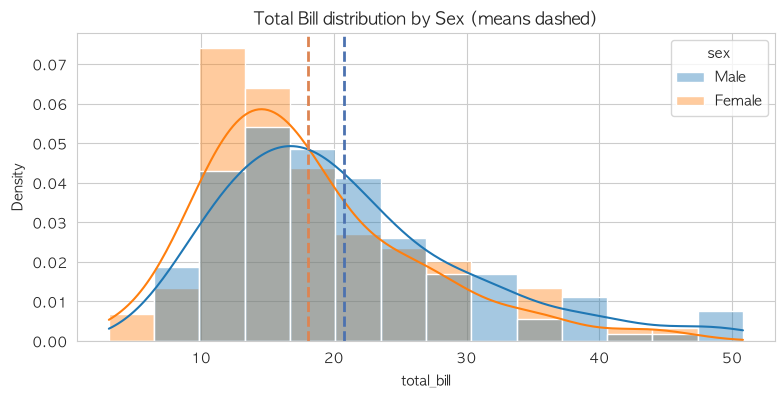

두 분포가 겹치는 정도가 클수록 '차이가 우연일' 여지가 큽니다. 평균차 2.69달러.


In [10]:
# [C4] [그림] t-test가 비교하는 '두 분포' — 남녀 결제 금액
fig, ax = plt.subplots(figsize=(9, 4))                            # 그래프 하나를 그릴 도화지 준비
sns.histplot(data=tips, x="total_bill", hue="sex", kde=True, stat="density",  # 히스토그램 — 값이 어디에 몰려 있나
             common_norm=False, alpha=0.4, ax=ax)
ax.axvline(male.mean(),   color="#4C72B0", ls="--", lw=2)
ax.axvline(female.mean(), color="#DD8452", ls="--", lw=2)
ax.set_title("Total Bill distribution by Sex (means dashed)")
plt.show()
print(f"두 분포가 겹치는 정도가 클수록 '차이가 우연일' 여지가 큽니다. 평균차 {male.mean()-female.mean():.2f}달러.")

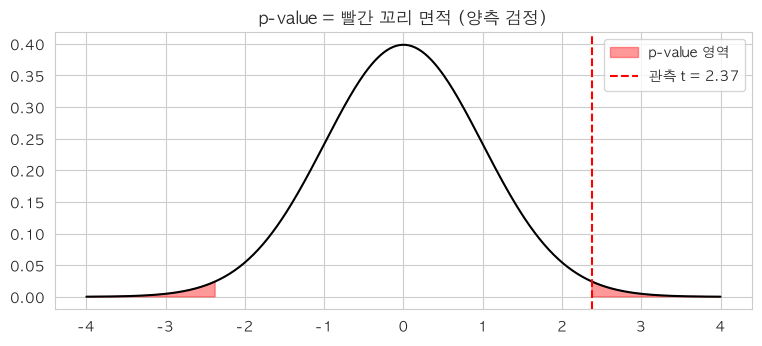

관측 t보다 더 극단적인 값이 H0(차이 없음)에서 나올 확률 = p-value


In [9]:
# [C5] [도식] p-value = t 분포에서 '관측값보다 극단적인' 꼬리 면적
dfree = len(male) + len(female) - 2
xx = np.linspace(-4, 4, 400)                                      # 구간을 균등 간격으로 쪼갠 x축 값
t_obs, _ = stats.ttest_ind(male, female, equal_var=False)         # 두 독립 집단의 평균 비교 (equal_var=False면 Welch)
fig, ax = plt.subplots(figsize=(9, 3.6))                          # 그래프 하나를 그릴 도화지 준비
ax.plot(xx, stats.t.pdf(xx, dfree), "k", lw=1.5)
ax.fill_between(xx, stats.t.pdf(xx, dfree), where=(np.abs(xx) >= abs(t_obs)),  # 곡선 아래 영역을 색으로 채움(= 면적은 확률)
                color="red", alpha=0.4, label="p-value 영역")
ax.axvline(t_obs, color="red", ls="--", label=f"관측 t = {t_obs:.2f}")  # 세로 기준선 표시
ax.set_title("p-value = 빨간 꼬리 면적 (양측 검정)"); ax.legend(); plt.show()
print("관측 t보다 더 극단적인 값이 H0(차이 없음)에서 나올 확률 = p-value")

sex   
Male      157
Female     87
Name: count, dtype: int64
남성 n = 157 왜도 = 1.1
여성 n = 87 왜도 = 1.13


<Axes: xlabel='total_bill', ylabel='Density'>

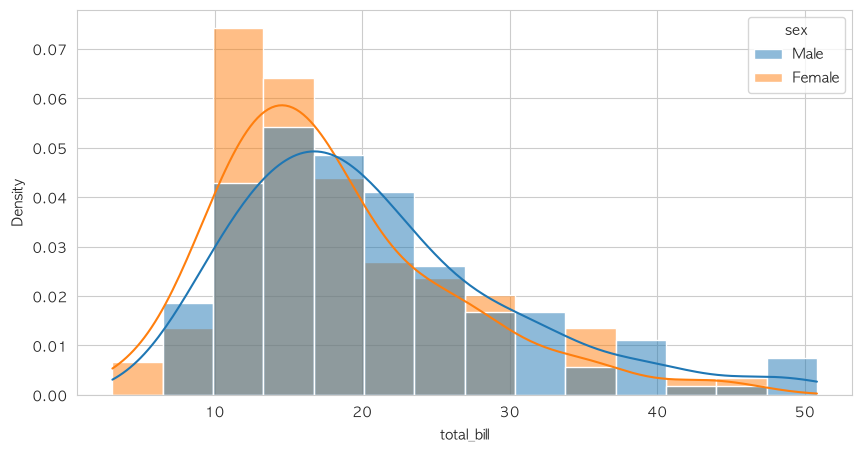

In [14]:
print(tips[["sex"]].value_counts())   # 집단별 표본 수
# 손님 식별자가 없으므로, 반복 방문 여부는 데이터 설명서로 확인해야 합니다.

for name, g in [("남성", male), ("여성", female)]:
    print(name, "n =", len(g), "왜도 =", round(g.skew(), 2))
sns.histplot(data=tips, x="total_bill", hue="sex", kde=True, stat="density", common_norm=False)

In [15]:
print("남성 분산:", round(male.var(), 2), " 여성 분산:", round(female.var(), 2))
print(stats.levene(male, female))   # p가 크면 등분산을 기각하지 못함

남성 분산: 85.5  여성 분산: 64.15
LeveneResult(statistic=np.float64(1.631715567905501), pvalue=np.float64(0.20269005267784004))


In [12]:
# [C6] [확인] 같은 데이터 — 양측 vs 단측 p-value
g_dinner = tips[tips["time"] == "Dinner"]["total_bill"]
g_lunch  = tips[tips["time"] == "Lunch"]["total_bill"]

t_two = stats.ttest_ind(g_dinner, g_lunch)                          # 양측 (기본)
t_one = stats.ttest_ind(g_dinner, g_lunch, alternative="greater")  # 단측 (저녁 > 점심)
print(f"양측검정 : t = {t_two.statistic:6.3f},  p = {t_two.pvalue:.4f}")
print(f"단측검정 : t = {t_one.statistic:6.3f},  p = {t_one.pvalue:.4f}   (방향 가설: 저녁 > 점심)")
print()
print("→ 같은 t값인데 단측 p가 양측 p의 약 절반입니다(한쪽 꼬리만 보므로).")

양측검정 : t =  2.898,  p = 0.0041
단측검정 : t =  2.898,  p = 0.0021   (방향 가설: 저녁 > 점심)

→ 같은 t값인데 단측 p가 양측 p의 약 절반입니다(한쪽 꼬리만 보므로).


In [17]:
# 1) 불리언 인덱싱으로 Lunch / Dinner의 total_bill 시리즈 만들기
lunch  = tips.loc[tips["time"] == "Lunch",  "total_bill"]
dinner = tips.loc[tips["time"] == "Dinner", "total_bill"]
alpha  = 0.05

# 2) 두 독립 집단의 평균 비교: Welch t-test (분산이 같다고 확신할 수 없으므로)
t, p = stats.ttest_ind(lunch, dinner, equal_var=False)

# 3) [5] 판정: p-value와 유의수준 0.05 비교
print(f"[1] H0: 점심 = 저녁   vs   H1: 점심 ≠ 저녁 (양측검정)")
print(f"    점심 평균 {lunch.mean():.2f} (n={len(lunch)})  /  저녁 평균 {dinner.mean():.2f} (n={len(dinner)})")
print(f"[4] t = {t:.2f},  p = {p:.3f}")
print(f"[5] p {'<' if p < alpha else '≥'} α({alpha}) → H0 {'기각' if p < alpha else '기각 못함'}")

# 4) [6] 비즈니스 해석 한 줄
if p < alpha:
    print("[6] 점심과 저녁의 결제 금액 평균 차이는 통계적으로 유의하다. "
          "(방향과 크기는 신뢰구간으로 따로 확인)")
else:
    print("[6] 점심과 저녁의 결제 금액 평균 차이는 우연으로 설명될 수 있다.")

# 3) (생각해보기) 답:
# 표본이 10건씩이면 표준오차가 커져 t값이 작아지고 p값이 0.05를 넘을 가능성이 크다.
# 실제 차이가 있어도 놓치는 제2종 오류(검정력 부족)가 생길 수 있어,
# 같은 결론이 나온다고 보장할 수 없다. 자세한 시뮬레이션은 Part 4에서 확인.

[1] H0: 점심 = 저녁   vs   H1: 점심 ≠ 저녁 (양측검정)
    점심 평균 17.17 (n=68)  /  저녁 평균 20.80 (n=176)
[4] t = -3.12,  p = 0.002
[5] p < α(0.05) → H0 기각
[6] 점심과 저녁의 결제 금액 평균 차이는 통계적으로 유의하다. (방향과 크기는 신뢰구간으로 따로 확인)


In [20]:
# ============================================================
# [C8] 1종·2종 오류 시뮬레이션
#
# 핵심 아이디어:
#   실제 데이터에서는 "진짜 차이가 있는지"를 모릅니다.
#   그래서 우리가 '정답을 정해 둔 가짜 세계'를 만들고,
#   검정을 2000번 돌려서 "판정이 얼마나 자주 맞는지/틀리는지"를 셉니다.
#
#   - 정답 없음 상황 → 검정이 잘못 "차이 있다"고 할 비율 = 1종 오류율 (α)
#   - 정답 있음 상황 → 검정이 "차이 있다"고 맞출 비율   = 검정력 (1 - β)
# ============================================================

np.random.seed(42)              # 난수를 고정 → 실행할 때마다 같은 결과가 나옴 (재현성)
N_SIM, n = 2000, 30             # 시뮬레이션 반복 횟수 2000번, 한 집단 표본 크기 30

# ------------------------------------------------------------
# (A) 진짜 차이가 '없을' 때 → 1종 오류율을 확인
#   두 집단 모두 평균 50, 표준편차 10 → 정답은 "차이 없음"(H0 참)
#   여기서 p < 0.05 가 나오면 "차이 있다"고 잘못 말한 것 = 1종 오류
# ------------------------------------------------------------
false_pos = np.mean([
    stats.ttest_ind(
        np.random.normal(50, 10, n),   # 집단 1: 평균 50인 가상 표본 30개 생성
        np.random.normal(50, 10, n),   # 집단 2: 평균 50인 가상 표본 30개 생성 (집단 1과 같은 분포)
    ).pvalue < 0.05                    # p < 0.05 이면 True(=잘못된 유의 판정), 아니면 False
    for _ in range(N_SIM)              # 위 과정을 2000번 반복
])                                     # True/False 평균 = "잘못 유의 판정한 비율"

# ------------------------------------------------------------
# (B) 진짜 차이가 '있을' 때 → 검정력(맞게 찾아낸 비율)을 확인
#   집단 1 평균 55, 집단 2 평균 50 → 정답은 "차이 있음"(H0 거짓)
#   여기서 p < 0.05 가 나오면 "차이 있다"고 제대로 찾은 것 = 검정력
# ------------------------------------------------------------
power = np.mean([
    stats.ttest_ind(
        np.random.normal(55, 10, n),   # 집단 1: 평균 55 (진짜로 5점 높게 설정)
        np.random.normal(50, 10, n),   # 집단 2: 평균 50
    ).pvalue < 0.05                    # p < 0.05 이면 True(=차이를 찾아냄), 아니면 False(=놓침)
    for _ in range(N_SIM)
])                                     # 평균 = 차이를 찾아낸 비율 = 검정력

# ------------------------------------------------------------
# 결과 해석
#   (A) 결과가 약 5% 근처 → 검정이 "없는 차이"를 5%만큼 잘못 찾음 = α 설정대로 작동
#   (B) 결과가 높을수록 좋음 → 차이가 있을 때 잘 찾는 능력
#   1 - power = 차이가 있는데도 놓친 비율 = 2종 오류율 (β)
# ------------------------------------------------------------
print(f"진짜 차이 없음 → 유의 판정 {false_pos:5.1%}   (≈ α=5%, 1종 오류)")
print(f"진짜 차이 있음 → 유의 판정 {power:5.1%}   (= 검정력 ; 나머지 {1-power:.0%}는 2종 오류)")

진짜 차이 없음 → 유의 판정  4.6%   (≈ α=5%, 1종 오류)
진짜 차이 있음 → 유의 판정 46.8%   (= 검정력 ; 나머지 53%는 2종 오류)


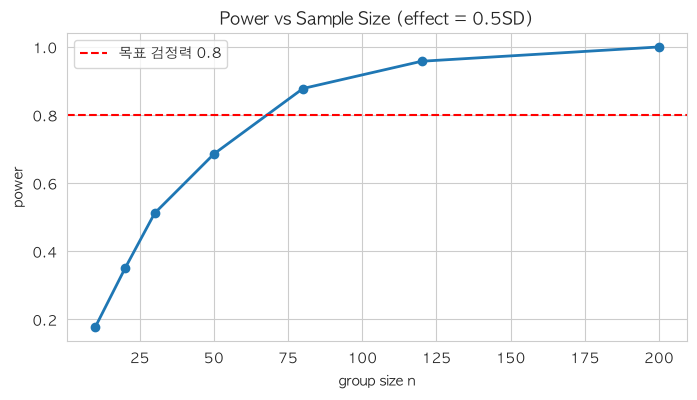

같은 효과라도 표본이 커지면 검정력이 빠르게 1.0에 다가갑니다.


In [21]:
# [C9] [그림] 검정력 곡선 — 표본이 커질수록 진짜 차이를 잘 잡는다
np.random.seed(42)                                                # 재현성: 난수를 항상 같게 고정
ns = [10, 20, 30, 50, 80, 120, 200]
powers = [np.mean([stats.ttest_ind(np.random.normal(55, 10, n),   # 두 독립 집단의 평균 비교 (equal_var=False면 Welch)
                                   np.random.normal(50, 10, n)).pvalue < 0.05
                   for _ in range(500)]) for n in ns]
fig, ax = plt.subplots(figsize=(8, 4))                            # 그래프 하나를 그릴 도화지 준비
ax.plot(ns, powers, "o-", lw=2)
ax.axhline(0.8, color="red", ls="--", label="목표 검정력 0.8")         # 가로 기준선 표시
ax.set_xlabel("group size n"); ax.set_ylabel("power")
ax.set_title("Power vs Sample Size (effect = 0.5SD)"); ax.legend(); plt.show()
print("같은 효과라도 표본이 커지면 검정력이 빠르게 1.0에 다가갑니다.")

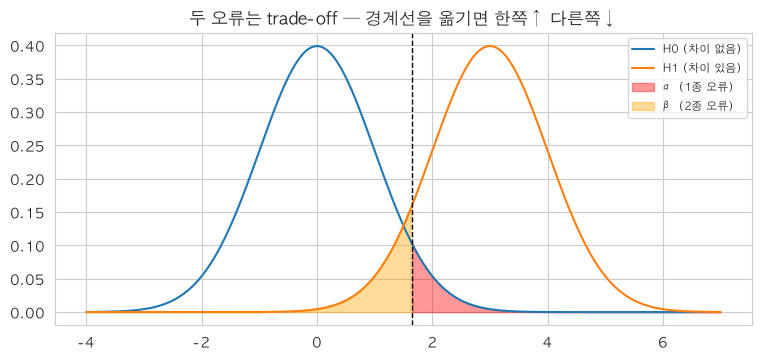

In [22]:
# [C10] [도식] 1종(α)·2종(β) 오류 — 두 가설 분포의 겹침
xx = np.linspace(-4, 7, 400)                                      # 구간을 균등 간격으로 쪼갠 x축 값
crit = stats.norm.ppf(0.95)
fig, ax = plt.subplots(figsize=(9, 3.8))                          # 그래프 하나를 그릴 도화지 준비
ax.plot(xx, stats.norm.pdf(xx, 0, 1), label="H0 (차이 없음)")
ax.plot(xx, stats.norm.pdf(xx, 3, 1), label="H1 (차이 있음)")
ax.fill_between(xx, stats.norm.pdf(xx, 0, 1), where=(xx >= crit), color="red",    alpha=0.4, label="α (1종 오류)")  # 곡선 아래 영역을 색으로 채움(= 면적은 확률)
ax.fill_between(xx, stats.norm.pdf(xx, 3, 1), where=(xx <  crit), color="orange", alpha=0.4, label="β (2종 오류)")  # 곡선 아래 영역을 색으로 채움(= 면적은 확률)
ax.axvline(crit, color="k", ls="--", lw=1)                        # 세로 기준선 표시
ax.set_title("두 오류는 trade-off — 경계선을 옮기면 한쪽↑ 다른쪽↓")
ax.legend(fontsize=8); plt.show()

In [24]:
# ============================================================
# [문제] 표본 크기(n)에 따른 검정력 변화 + 각 케이스의 t, p, 1종 오류
#
# 핵심 아이디어:
#   - 검정력 : "진짜 차이(55 vs 50)가 있을 때" 차이를 찾아낸 비율
#   - 1종 오류: "진짜 차이가 없을 때(50 vs 50)" 잘못 차이가 있다고 한 비율
#   - t, p   : 시뮬레이션에서 나온 검정통계량과 p값의 평균(요약용)
# ============================================================

np.random.seed(42)                # 재현성: 반복 전에 한 번 고정 → 같은 실행이면 같은 결과
N_SIM = 2000                      # 각 n마다 시뮬레이션 반복 횟수
alpha = 0.05                      # 유의수준: p < 0.05면 "차이 있다"고 판정
sd = 10                           # 두 집단 공통 표준편차

rows = []                         # 결과를 한 행씩 모아 둘 리스트 (나중에 표로 출력)

for n in [30, 100, 300]:          # 표본 크기를 30 → 100 → 300으로 바꿔 가며 비교

    # ---------- (B) 진짜 차이가 있는 세계: 평균 55 vs 50 ----------
    t_list, p_list = [], []       # 이 n에서 나온 t값, p값을 매번 기록
    hits = 0                      # 차이를 찾아낸(p<0.05) 횟수 세기

    for _ in range(N_SIM):
        a = np.random.normal(55, sd, n)   # 집단 A: 평균 55 (진짜 차이 있음)
        b = np.random.normal(50, sd, n)   # 집단 B: 평균 50
        res = stats.ttest_ind(a, b, equal_var=False)   # Welch t-test 실행
        t_list.append(res.statistic)      # 이번 시뮬레이션의 t값 저장
        p_list.append(res.pvalue)         # 이번 시뮬레이션의 p값 저장
        if res.pvalue < alpha:            # p < 0.05 → 진짜 차이를 찾아냄
            hits += 1

    power = hits / N_SIM                  # 검정력 = 찾아낸 비율
    mean_t = np.mean(t_list)              # 2000번 t값의 평균 (보통 양수 쪽으로 치우침)
    mean_p = np.mean(p_list)              # 2000번 p값의 평균 (요약 참고용)

    # ---------- (A) 진짜 차이가 없는 세계: 평균 50 vs 50 ----------
    false_hits = 0                        # 차이가 없는데 있다고 한 횟수 세기
    for _ in range(N_SIM):
        a0 = np.random.normal(50, sd, n)  # 집단 A: 평균 50
        b0 = np.random.normal(50, sd, n)  # 집단 B: 평균 50 (차이 없음)
        if stats.ttest_ind(a0, b0, equal_var=False).pvalue < alpha:
            false_hits += 1               # 잘못된 유의 판정 누적 = 1종 오류

    type1 = false_hits / N_SIM            # 1종 오류율 (이론상 약 0.05)

    rows.append({                         # 이 n의 결과를 한 행으로 저장
        "n": n,
        "평균 t": round(mean_t, 2),
        "평균 p": round(mean_p, 4),
        "검정력": f"{power:.1%}",
        "2종 오류": f"{1 - power:.1%}",
        "1종 오류": f"{type1:.1%}",
    })

# 표로 한 번에 출력
result_table = pd.DataFrame(rows)
print(result_table.to_string(index=False))

# ------------------------------------------------------------
# [2) 해석] 표본을 키우면 검정력이 오르는 이유 (한 줄)
#   → 표본이 커지면 표준오차(σ/√n)가 줄어 같은 평균 차이(5)가 더 또렷한 신호가 되므로
#     우연한 흔들림에 묻히지 않고 p < 0.05로 잡히는 비율이 높아진다.
#
# [3) 생각해보기] 효과는 작지만 표본이 매우 크면 p는?
#   → 표준오차가 아주 작아져 t값이 커지고 p가 0.05보다 작아질 수 있다.
#     p는 "차이가 있는가"만 말하고 "차이가 얼마나 큰가"는 말하지 않는다.
#     그래서 Part 7에서 효과크기(Cohen's d)나 신뢰구간으로 실질적 의미를 따로 판단한다.
# ------------------------------------------------------------

  n  평균 t   평균 p    검정력 2종 오류 1종 오류
 30  1.98 0.1552  48.0% 52.0%  5.3%
100  3.56 0.0129  94.5%  5.4%  5.1%
300  6.17 0.0000 100.0%  0.0%  5.2%
